In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
cmap_fips = [
    "17031",  # Cook
    "17043",  # DuPage
    "17089",  # Kane
    "17093",  # Kendall
    "17097",  # Lake
    "17111",  # McHenry
    "17197",  # Will
]

truck_source_types = {
    52: "Single Unit Short Haul",
    53: "Single Unit Long Haul",
    61: "Combination Short Haul",
    62: "Combination Long Haul",}

In [4]:
# read the annual vehicle population file
vpop_file = "VPOP_2022v1_full_annual_20240301_18jun2024_nf_v6.csv"

vpop_columns = [
    "country_cd", "region_cd", "tribal_code", "census_tract_cd", "shape_id",
    "scc", "CD", "MSR", "activity_type", "ann_parm_value", "calc_year",
    "date_updated", "data_set_id", "jan_value", "feb_value", "mar_value",
    "apr_value", "may_value", "jun_value", "jul_value", "aug_value",
    "sep_value", "oct_value", "nov_value", "dec_value", "comment"
]

vpop = pd.read_csv(vpop_file, sep=",", comment="#", header=None, names=vpop_columns, dtype={"region_cd": str, "scc": str})

# pull the MOVES source type from the SCC
vpop["source_type"] = vpop["scc"].str[4:6].astype(int)

# keep the four truck types in the seven CMAP counties
cmap_truck_vpop = vpop[
    vpop["region_cd"].isin(cmap_fips)
    & vpop["source_type"].isin(truck_source_types)
    & (vpop["activity_type"] == "POP")
].copy()

# sum vehicle population by county and truck type
county_source_vpop = cmap_truck_vpop.groupby(["region_cd", "source_type"])["ann_parm_value"].sum().unstack(fill_value=0)

print("\nVEHICLE POPULATION BY COUNTY")
display(county_source_vpop)

# sum across all seven CMAP counties
cmap_source_vpop = county_source_vpop.sum(axis=0)

print("\nTOTAL CMAP VEHICLE POPULATION")
for source_type, population in cmap_source_vpop.items():
    print(f"{source_type} - {truck_source_types[source_type]}: {population:,.0f} vehicles")

# create a simple fleet summary
cmap_vpop_summary = pd.DataFrame({
    "Source Type": cmap_source_vpop.index,
    "Vehicle Type": [truck_source_types[x] for x in cmap_source_vpop.index],
    "Vehicle Population": cmap_source_vpop.values,
})

# calculate each truck type's share of the CMAP truck fleet
cmap_vpop_summary["Fleet Share (%)"] = cmap_vpop_summary["Vehicle Population"] / cmap_vpop_summary["Vehicle Population"].sum() * 100

print("\nCMAP TRUCK FLEET SUMMARY")
display(cmap_vpop_summary)


VEHICLE POPULATION BY COUNTY


source_type,52,53,61,62
region_cd,,,,
17031,60667.750012,2723.510001,6782.550003,10486.340338
17043,15349.240000,691.980000,1688.380000,2568.709396
17089,8037.409999,363.740000,891.430000,1360.660000
17093,1647.870000,75.960000,172.220000,190.850000
17097,11194.069998,511.410000,1167.280000,1525.172613
17111,5003.550001,227.480000,561.610000,835.350000
17197,12608.799997,564.070000,1438.390000,2094.790000



TOTAL CMAP VEHICLE POPULATION
52 - Single Unit Short Haul: 114,509 vehicles
53 - Single Unit Long Haul: 5,158 vehicles
61 - Combination Short Haul: 12,702 vehicles
62 - Combination Long Haul: 19,062 vehicles

CMAP TRUCK FLEET SUMMARY


,Source Type,Vehicle Type,Vehicle Population,Fleet Share (%)
0,52,Single Unit Short Haul,114508.690007,75.617947
1,53,Single Unit Long Haul,5158.150002,3.406280
2,61,Combination Short Haul,12701.860002,8.387910
3,62,Combination Long Haul,19061.872347,12.587863


In [7]:
# read the annual vehicle miles traveled file
vmt_file = "VMT_2022v1_full_annual_20240226_monthly_18jun2024_nf_v4.csv"

vmt_columns = [
    "country_cd", "region_cd", "tribal_code", "census_tract_cd", "shape_id",
    "scc", "CD", "MSR", "activity_type", "ann_parm_value", "calc_year",
    "date_updated", "data_set_id", "jan_value", "feb_value", "mar_value",
    "apr_value", "may_value", "jun_value", "jul_value", "aug_value",
    "sep_value", "oct_value", "nov_value", "dec_value", "comment"
]

# skip the metadata lines and add the column names manually
vmt = pd.read_csv(vmt_file, sep=",", comment="#", header=None, names=vmt_columns, dtype={"region_cd": str, "scc": str})

vmt.head()

vmt["source_type"] = (vmt["scc"].str[4:6].astype(int))
cmap_truck_vmt = vmt[vmt["region_cd"].isin(cmap_fips) & vmt["source_type"].isin(truck_source_types)].copy()

county_source_vmt = (
    cmap_truck_vmt
    .groupby(["region_cd", "source_type"])["ann_parm_value"]
    .sum()
    .unstack(fill_value=0))

display(county_source_vmt)

source_type,52,53,61,62
region_cd,,,,
17031,9.539875e+08,6.515359e+07,4.403020e+08,1.572951e+09
17043,2.203859e+08,1.504750e+07,1.080516e+08,3.853064e+08
17089,1.153268e+08,7.892739e+06,5.097061e+07,2.026952e+08
17093,2.544536e+07,1.770781e+06,8.215573e+06,2.200247e+07
17097,1.624764e+08,1.122656e+07,6.968953e+07,2.287759e+08
17111,6.971020e+07,4.793104e+06,2.759435e+07,1.129724e+08
17197,1.651625e+08,1.124688e+07,8.055364e+07,2.932691e+08


In [6]:
AGE_FILE = "cdb17031y2022moves_age_dist.csv"
VMT_FILE = "VMT_DIST_Moves4.xlsx"
VMT_SHEET = "MOVES % VMTs"
BASE_YEAR = 2022

In [8]:
# sum annual VMT across all seven CMAP counties
cmap_source_vmt = county_source_vmt.sum(axis=0)

# set the MOVES source types, VMT columns, and plot titles
VEHICLES = [
    {"source_type": 52, "vmt_col": "su_short", "title": "Single-Unit\nShort Haul"},
    {"source_type": 53, "vmt_col": "su_long", "title": "Single-Unit\nLong Haul"},
    {"source_type": 61, "vmt_col": "ct_short", "title": "Combination\nShort Haul"},
    {"source_type": 62, "vmt_col": "ct_long", "title": "Combination\nLong Haul"},]

# add the total annual VMT for each truck type
for vehicle in VEHICLES:
    vehicle["annual_vmt"] = cmap_source_vmt.loc[vehicle["source_type"]]

# labels for the vehicle model-year groups
BIN_LABELS = ["Pre-2010", "2010–2013", "2014–2016", "2017–2019", "2020–2021", "2022"]

VEHICLES

[{'source_type': 52,
  'vmt_col': 'su_short',
  'title': 'Single-Unit\nShort Haul',
  'annual_vmt': 1712494640.44456},
 {'source_type': 53,
  'vmt_col': 'su_long',
  'title': 'Single-Unit\nLong Haul',
  'annual_vmt': 117131147.5099427},
 {'source_type': 61,
  'vmt_col': 'ct_short',
  'title': 'Combination\nShort Haul',
  'annual_vmt': 785377277.8069749},
 {'source_type': 62,
  'vmt_col': 'ct_long',
  'title': 'Combination\nLong Haul',
  'annual_vmt': 2817972492.6510005}]

In [10]:
def assign_model_year_group(year):
    """
    Assign an individual model year to the model-year groups
    used in both the fleet and VMT figures.
    Prob a more elloquent way of doing this, but alas. 
    """

    if year < 2010:
        return "Pre-2010"
    elif 2010 <= year <= 2013:
        return "2010–2013"
    elif 2014 <= year <= 2016:
        return "2014–2016"
    elif 2017 <= year <= 2019:
        return "2017–2019"
    elif 2020 <= year <= 2021:
        return "2020–2021"
    elif year == 2022:
        return "2022"
    else:
        return np.nan

In [11]:
age_df = pd.read_csv(AGE_FILE)

# Keep only calendar year 2022
age_df = age_df[
    age_df["yearID"] == BASE_YEAR
].copy()

# Keep only the four MHDV source types
age_df = age_df[
    age_df["sourceTypeID"].isin([52, 53, 61, 62])
].copy()


In [12]:
# convert vehicle age to model year
age_df["modelYear"] = BASE_YEAR - age_df["ageID"]

# assign each model year to a model-year group
age_df["modelYearGroup"] = age_df["modelYear"].apply(assign_model_year_group)

age_distributions = {}

for vehicle in VEHICLES:
    source_type = vehicle["source_type"]

    # keep the age distribution for this truck type
    d = age_df[age_df["sourceTypeID"] == source_type].copy()

    # sum the age fractions within each model-year group
    dist = d.groupby("modelYearGroup")["ageFraction"].sum().reindex(BIN_LABELS, fill_value=0)

    # check that the age fractions sum to approximately 1
    total = d["ageFraction"].sum()
    print(f"Source type {source_type} ageFraction total = {total:.8f}")

    if not np.isclose(total, 1.0, atol=1e-5):
        print(f"  WARNING: Source type {source_type} does not sum to 1.0.")

    # convert the MOVES age fractions to percentages without renormalizing
    age_distributions[source_type] = dist * 100

Source type 52 ageFraction total = 1.00000000
Source type 53 ageFraction total = 1.00000000
Source type 61 ageFraction total = 1.00000000
Source type 62 ageFraction total = 1.00000000


In [13]:
# read the model-year VMT distributions
vmt_raw = pd.read_excel(VMT_FILE, sheet_name=VMT_SHEET, header=None)

# keep the rows and columns containing the model-year data
data = vmt_raw.iloc[3:34, :].copy()

vmt_df = pd.DataFrame({
    "model_year": pd.to_numeric(data.iloc[:, 0], errors="coerce"),
    "su_short": pd.to_numeric(data.iloc[:, 2], errors="coerce"),
    "su_long": pd.to_numeric(data.iloc[:, 3], errors="coerce"),
    "ct_short": pd.to_numeric(data.iloc[:, 4], errors="coerce"),
    "ct_long": pd.to_numeric(data.iloc[:, 5], errors="coerce"),
}).dropna()

# assign each model year to a model-year group
vmt_df["modelYearGroup"] = vmt_df["model_year"].apply(assign_model_year_group)

VMT_COLUMNS = ["su_short", "su_long", "ct_short", "ct_long"]

# sum the VMT fractions within each model-year group
vmt_binned = vmt_df.groupby("modelYearGroup")[VMT_COLUMNS].sum().reindex(BIN_LABELS, fill_value=0)

print("\nAnnual VMT distribution totals:")

# check that the VMT fractions sum to approximately 1
for col in VMT_COLUMNS:
    total = vmt_binned[col].sum()
    print(f"{col}: {total:.8f}")

    if not np.isclose(total, 1.0, atol=1e-4):
        print(f"  WARNING: {col} does not sum to 1.0.")

# convert the VMT fractions to percentages without renormalizing
vmt_binned_pct = vmt_binned * 100


Annual VMT distribution totals:
su_short: 1.00000000
su_long: 1.00000000
ct_short: 1.00000000
ct_long: 1.00000000


In [14]:
print("\nANNUAL VMT DISTRIBUTIONS")

for vehicle in VEHICLES:
    source_type = vehicle["source_type"]
    vmt_col = vehicle["vmt_col"]
    title = vehicle["title"].replace("\n", " ")
    total_vmt = vehicle["annual_vmt"]
    vmt_pct = vmt_binned_pct[vmt_col]

    print(f"\n{title}")
    print(f"Total annual VMT: {total_vmt:,.0f}")

    # print the percentage and annual VMT for each model-year group
    for bin_label in BIN_LABELS:
        pct = vmt_pct.loc[bin_label]
        bin_vmt = total_vmt * pct / 100
        print(f"{bin_label:<12} {pct:6.2f}%   {bin_vmt:>15,.0f} VMT/yr")


ANNUAL VMT DISTRIBUTIONS

Single-Unit Short Haul
Total annual VMT: 1,712,494,640
Pre-2010      21.93%       375,533,028 VMT/yr
2010–2013     16.85%       288,622,400 VMT/yr
2014–2016     17.30%       296,254,562 VMT/yr
2017–2019     21.29%       364,644,073 VMT/yr
2020–2021     15.08%       258,293,718 VMT/yr
2022           7.54%       129,146,859 VMT/yr

Single-Unit Long Haul
Total annual VMT: 117,131,148
Pre-2010      19.55%        22,896,500 VMT/yr
2010–2013     16.07%        18,821,646 VMT/yr
2014–2016     17.70%        20,729,094 VMT/yr
2017–2019     22.54%        26,397,260 VMT/yr
2020–2021     16.10%        18,857,765 VMT/yr
2022           8.05%         9,428,883 VMT/yr

Combination Short Haul
Total annual VMT: 785,377,278
Pre-2010      15.92%       125,058,440 VMT/yr
2010–2013     16.79%       131,852,286 VMT/yr
2014–2016     18.49%       145,248,996 VMT/yr
2017–2019     23.55%       184,985,952 VMT/yr
2020–2021     16.83%       132,154,402 VMT/yr
2022           8.41%        6

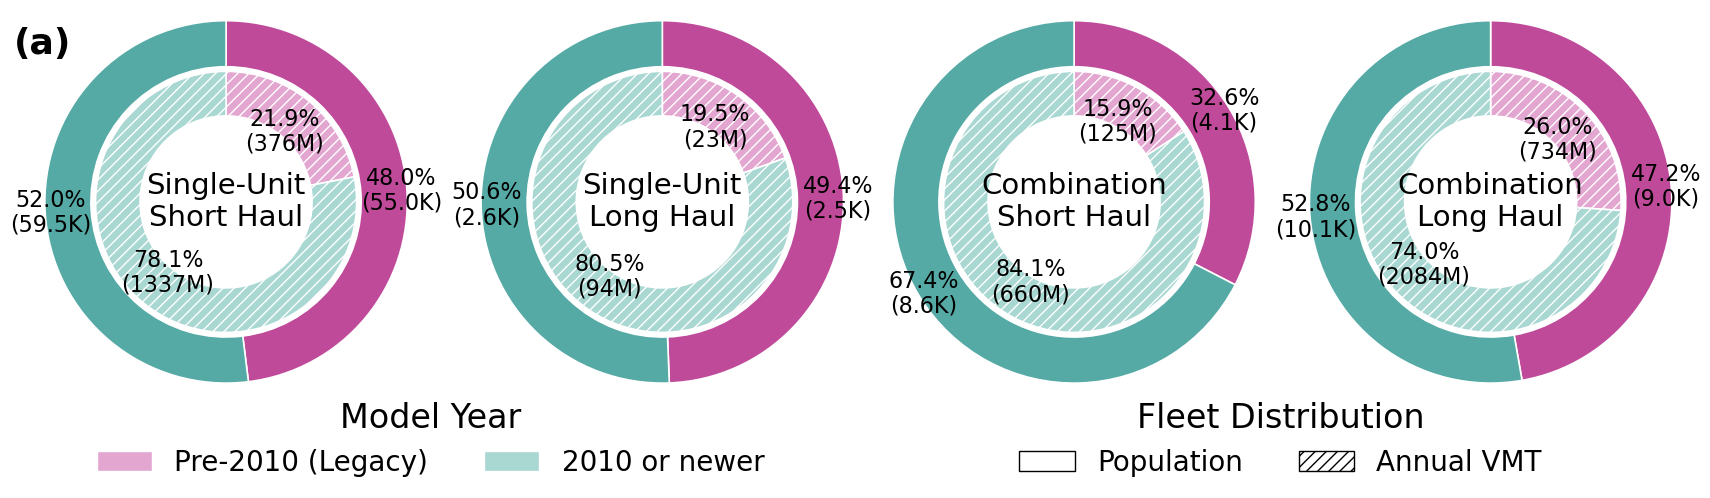

In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# get the total annual VMT and vehicle population for each truck type
cmap_source_vmt = county_source_vmt.sum(axis=0)
cmap_source_vpop = county_source_vpop.sum(axis=0)

# set the MOVES source types, VMT columns, and plot titles
VEHICLES = [
    {"source_type": 52, "vmt_col": "su_short", "title": "Single-Unit\nShort Haul"},
    {"source_type": 53, "vmt_col": "su_long", "title": "Single-Unit\nLong Haul"},
    {"source_type": 61, "vmt_col": "ct_short", "title": "Combination\nShort Haul"},
    {"source_type": 62, "vmt_col": "ct_long", "title": "Combination\nLong Haul"},
]

# colors for pre-2010 and newer trucks
outer_colors = ["#C04A9A", "#55AAA5"]
inner_colors = ["#E3A6D0", "#A9D7D2"]

fig, axs = plt.subplots(1, 4, figsize=(17, 5), constrained_layout=True)

for ax, vehicle in zip(axs, VEHICLES):
    source_type = vehicle["source_type"]
    annual_vmt = cmap_source_vmt.loc[source_type]
    vehicle_pop = cmap_source_vpop.loc[source_type]

    # group the fleet and VMT into pre-2010 and 2010 or newer
    age_full = age_distributions[source_type]
    age_dist = [age_full["Pre-2010"], age_full.drop("Pre-2010").sum()]

    vmt_full = vmt_binned_pct[vehicle["vmt_col"]]
    vmt_dist = [vmt_full["Pre-2010"], vmt_full.drop("Pre-2010").sum()]

    # show the percentage and actual vehicle population
    def pop_label(pct):
        return f"{pct:.1f}%\n({vehicle_pop * pct / 100 / 1e3:.1f}K)"

    # show the percentage and actual annual VMT
    def vmt_label(pct):
        return f"{pct:.1f}%\n({annual_vmt * pct / 100 / 1e6:.0f}M)"

    _, _, outer_labels = ax.pie(
        age_dist, radius=1.18, colors=outer_colors, startangle=90,
        counterclock=False, autopct=pop_label, pctdistance=0.97,
        wedgeprops={"width": 0.30, "edgecolor": "white", "linewidth": 1.2}
    )

    inner_wedges, _, inner_labels = ax.pie(
        vmt_dist, radius=0.85, colors=inner_colors, startangle=90,
        counterclock=False, autopct=vmt_label, pctdistance=0.70,
        wedgeprops={"width": 0.29, "edgecolor": "white", "linewidth": 1.2}
    )

    # use hatching to distinguish VMT from vehicle population
    for wedge in inner_wedges:
        wedge.set_hatch("///")

    for label in outer_labels + inner_labels:
        label.set_fontsize(16)
        label.set_color("black")
        label.set_linespacing(1.1)

    ax.text(0, 0, vehicle["title"], ha="center", va="center", fontsize=21, linespacing=1.15)
    ax.set_aspect("equal")

# explain the model-year colors
model_year_legend = [
    Patch(facecolor=inner_colors[0], edgecolor="white", label="Pre-2010 (Legacy)"),
    Patch(facecolor=inner_colors[1], edgecolor="white", label="2010 or newer"),
]

# explain the outer and inner rings
metric_legend = [
    Patch(facecolor="white", edgecolor="black", label="Population"),
    Patch(facecolor="white", edgecolor="black", hatch="///", label="Annual VMT"),
]

fig.legend(handles=model_year_legend, title="Model Year", loc="lower center", bbox_to_anchor=(0.25, -0.1), frameon=False, fontsize=20, title_fontsize=24, ncol=2)
fig.legend(handles=metric_legend, title="Fleet Distribution", loc="lower center", bbox_to_anchor=(0.75, -0.1), frameon=False, fontsize=20, title_fontsize=24, ncol=2)

# add the panel label
fig.text(0.005, 0.85, "(a)", ha="left", va="top", fontsize=26, fontweight="bold")

plt.show()